In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from google.colab import files

In [3]:
uploaded = files.upload()
uploaded_names = list(uploaded.keys())

def find_uploaded_image(keyword, fallback_index):
  matches = [
      img_name for img_name in uploaded_names
      if keyword.lower() in img_name.lower()
  ]

  if matches:
    return '/content/' + matches[0]

  if fallback_index < len(uploaded_names):
    return '/content/' + uploaded_names[fallback_index]
  raise FileNotFoundError(f'Image Not Found: {keyword}')

blob_path = find_uploaded_image('blob.jpg', 0)
blob_size_path = find_uploaded_image('blob_size', 1)
blob_circularity_path = find_uploaded_image('blob_circularity', 2)
blob_convexity_path = find_uploaded_image('blob_convexity', 3)
blob_inertia_path = find_uploaded_image('blob_inertia', 4)
blob_threshold_path = find_uploaded_image('blob_threshold', 5)

print('Uploaded Images:', len(uploaded_names))

Saving blob.jpg to blob.jpg
Saving blob_Circularity.jpg to blob_Circularity.jpg
Saving blob_convexity.jpg to blob_convexity.jpg
Saving blob_inertia.jpg to blob_inertia.jpg
Saving blob_size.jpg to blob_size.jpg
Saving blob_Threshold.jpg to blob_Threshold.jpg
Uploaded Images: 6


In [5]:
def load_image(image_path):
  image = cv2.imread(image_path)

  if image is None:
    raise FileNotFoundError(f'Image Not Found: {image_path}')
  return image

def detect_and_draw(image, params):
  detector = cv2.SimpleBlobDetector_create(params)
  keypoints = detector.detect(image)

  simple_result = cv2.drawKeypoints(image, keypoints, np.array([]), (0, 0, 255))

  rich_result = cv2.drawKeypoints(image, keypoints, np.array([]), (0, 0, 255), cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

  return simple_result, rich_result, keypoints

def show_results(image, title, figure_size=(10, 10)):
  plt.figure(figsize=figure_size)

  for index, (image, title) in enumerate(zip([image], [title]), start=1):
    plt.subplot(1, len(Images), index)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(Title)
    plt.axis('off')

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

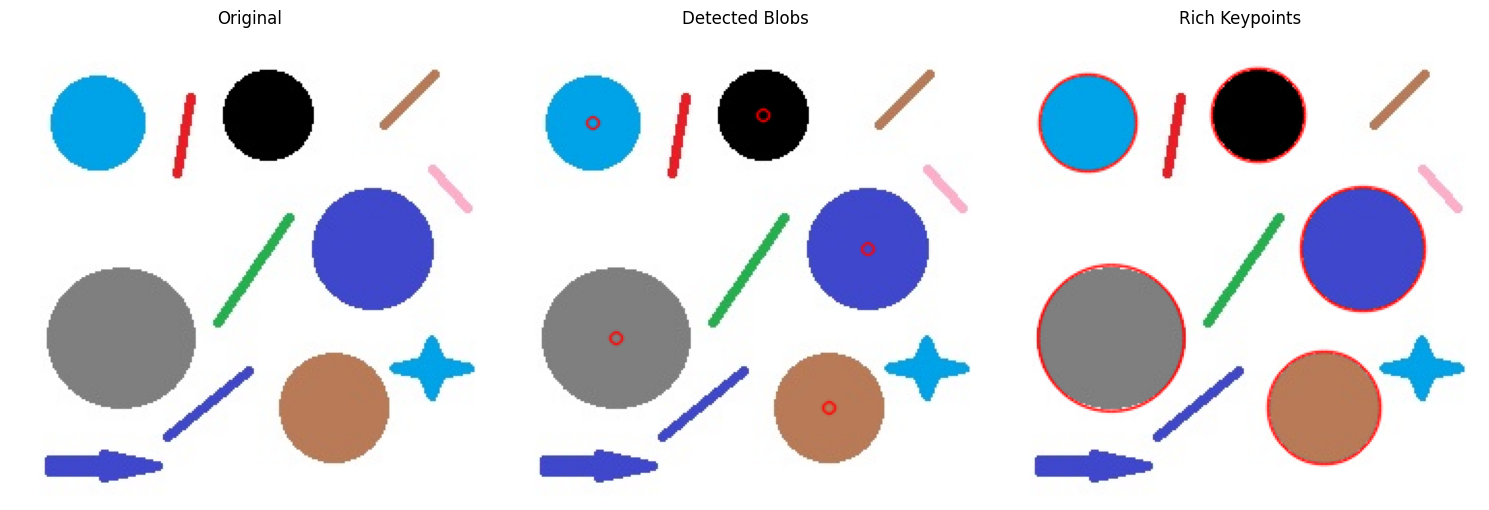

Default Detected Blobs: 5


In [11]:
default_image = load_image(blob_path)
default_params = cv2.SimpleBlobDetector_Params()

default_result, default_rich_result, default_keypoints = detect_and_draw(
    default_image,
    default_params
)

def show_results(images, titles, figure_size=(10, 10)):
  plt.figure(figsize=figure_size)

  for index, (img, title) in enumerate(zip(images, titles), start=1):
    plt.subplot(1, len(images), index)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')

  plt.tight_layout()
  plt.show()

show_results(
    [default_image, default_result, default_rich_result],
    ['Original', 'Detected Blobs', 'Rich Keypoints'],
    figure_size=(15, 7)
)

print('Default Detected Blobs:', len(default_keypoints))

In [12]:
for blob_id, keypoint in enumerate(default_keypoints, start=1):
  print(
      f'Blob {blob_id}: '
      f'center=({keypoint.pt[0]:.2f}, {keypoint.pt[1]:.2f}), '
      f'size={keypoint.size:.2f}'
  )

Blob 1: center=(133.02, 43.02), size=48.08
Blob 2: center=(187.05, 112.05), size=63.92
Blob 3: center=(57.01, 158.04), size=75.38
Blob 4: center=(45.03, 47.03), size=50.04
Blob 5: center=(167.02, 194.02), size=57.99


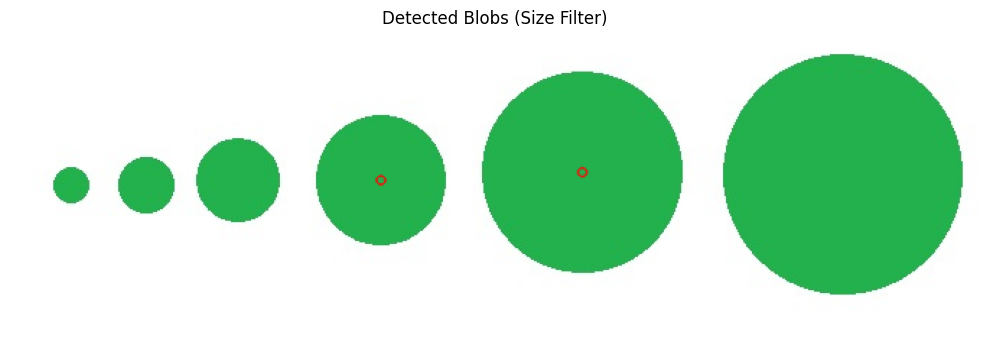

Detected Blobs (Size Filter): 2


In [15]:
size_image = load_image(blob_size_path)
size_params = cv2.SimpleBlobDetector_Params()
size_params.filterByArea = True
size_params.minArea = 5000
size_params.maxArea = 20000

size_result, size_rich_result, size_keypoints = detect_and_draw(
    size_image,
    size_params
)

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(size_result, cv2.COLOR_BGR2RGB))
plt.title('Detected Blobs (Size Filter)')
plt.axis('off')

plt.tight_layout()
plt.show()

print('Detected Blobs (Size Filter):', len(size_keypoints))

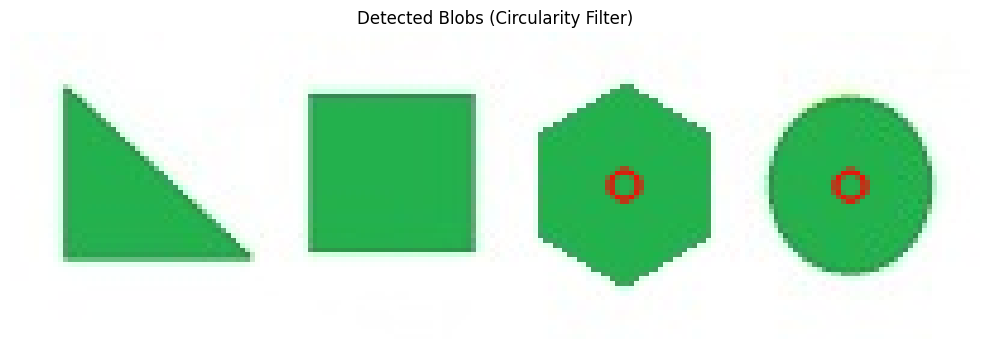

Detected Blobs (Circularity Filter): 2


In [18]:
circularity_image = load_image(blob_circularity_path)
circularity_params = cv2.SimpleBlobDetector_Params()
circularity_params.filterByCircularity = True
circularity_params.minCircularity = 0.84

circularity_result, circularity_rich_result, circularity_keypoints = detect_and_draw(
    circularity_image,
    circularity_params
)

plt.figure(figsize=(10, 7))

plt.imshow(cv2.cvtColor(circularity_result, cv2.COLOR_BGR2RGB))
plt.title('Detected Blobs (Circularity Filter)')
plt.axis('off')

plt.tight_layout()
plt.show()

print('Detected Blobs (Circularity Filter):', len(circularity_keypoints))

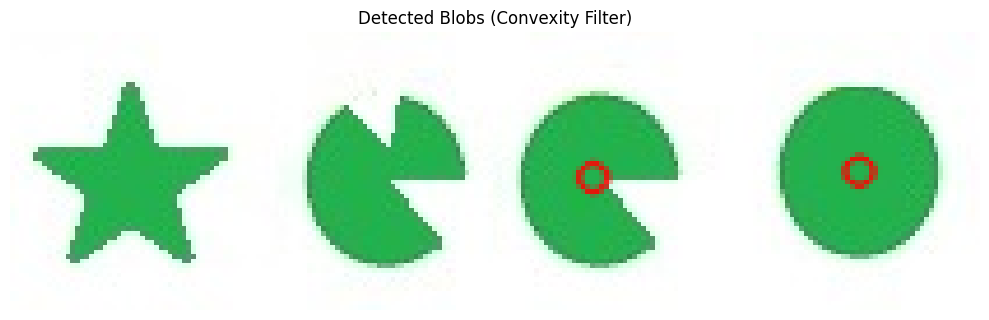

Detected Blobs (Convexity Filter): 2


In [19]:
convexity_image = load_image(blob_convexity_path)
convexity_params = cv2.SimpleBlobDetector_Params()
convexity_params.filterByConvexity = True
convexity_params.minConvexity = 0.85

convexity_result, convexity_rich_result, convexity_keypoints = detect_and_draw(
    convexity_image,
    convexity_params
)

plt.figure(figsize=(10, 7))

plt.imshow(cv2.cvtColor(convexity_result, cv2.COLOR_BGR2RGB))
plt.title('Detected Blobs (Convexity Filter)')
plt.axis('off')

plt.tight_layout()
plt.show()

print('Detected Blobs (Convexity Filter):', len(convexity_keypoints))

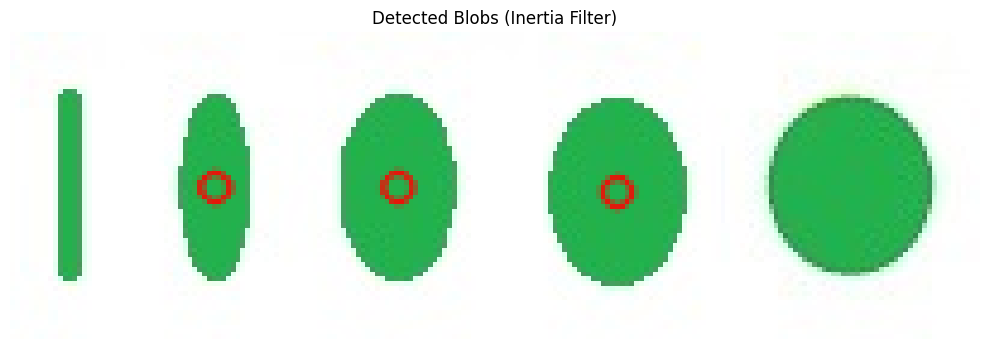

Detected Blobs (Inertia Filter): 3


In [20]:
inertia_image = load_image(blob_inertia_path)
inertia_params = cv2.SimpleBlobDetector_Params()
inertia_params.filterByInertia = True
inertia_params.minInertiaRatio = 0.03
inertia_params.maxInertiaRatio = 0.7

inertia_result, inertia_rich_result, inertia_keypoints = detect_and_draw(
    inertia_image,
    inertia_params)

plt.figure(figsize=(10, 7))

plt.imshow(cv2.cvtColor(inertia_result, cv2.COLOR_BGR2RGB))
plt.title('Detected Blobs (Inertia Filter)')
plt.axis('off')

plt.tight_layout()
plt.show()

print('Detected Blobs (Inertia Filter):', len(inertia_keypoints))

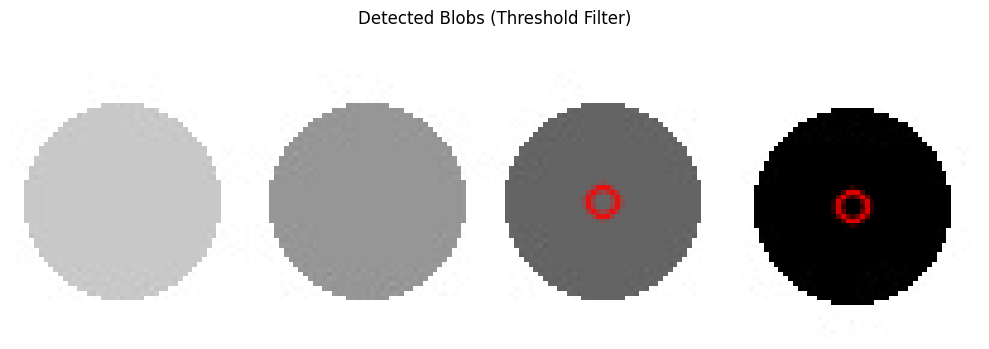

In [21]:
threshold_image = load_image(blob_threshold_path)
threshold_params = cv2.SimpleBlobDetector_Params()
threshold_params.maxThreshold = 150

threshold_result, threshold_rich_result, threshold_keypoints = detect_and_draw(
    threshold_image,
    threshold_params)

plt.figure(figsize=(10, 7))

plt.imshow(cv2.cvtColor(threshold_result, cv2.COLOR_BGR2RGB))
plt.title('Detected Blobs (Threshold Filter)')
plt.axis('off')

plt.tight_layout()
plt.show()

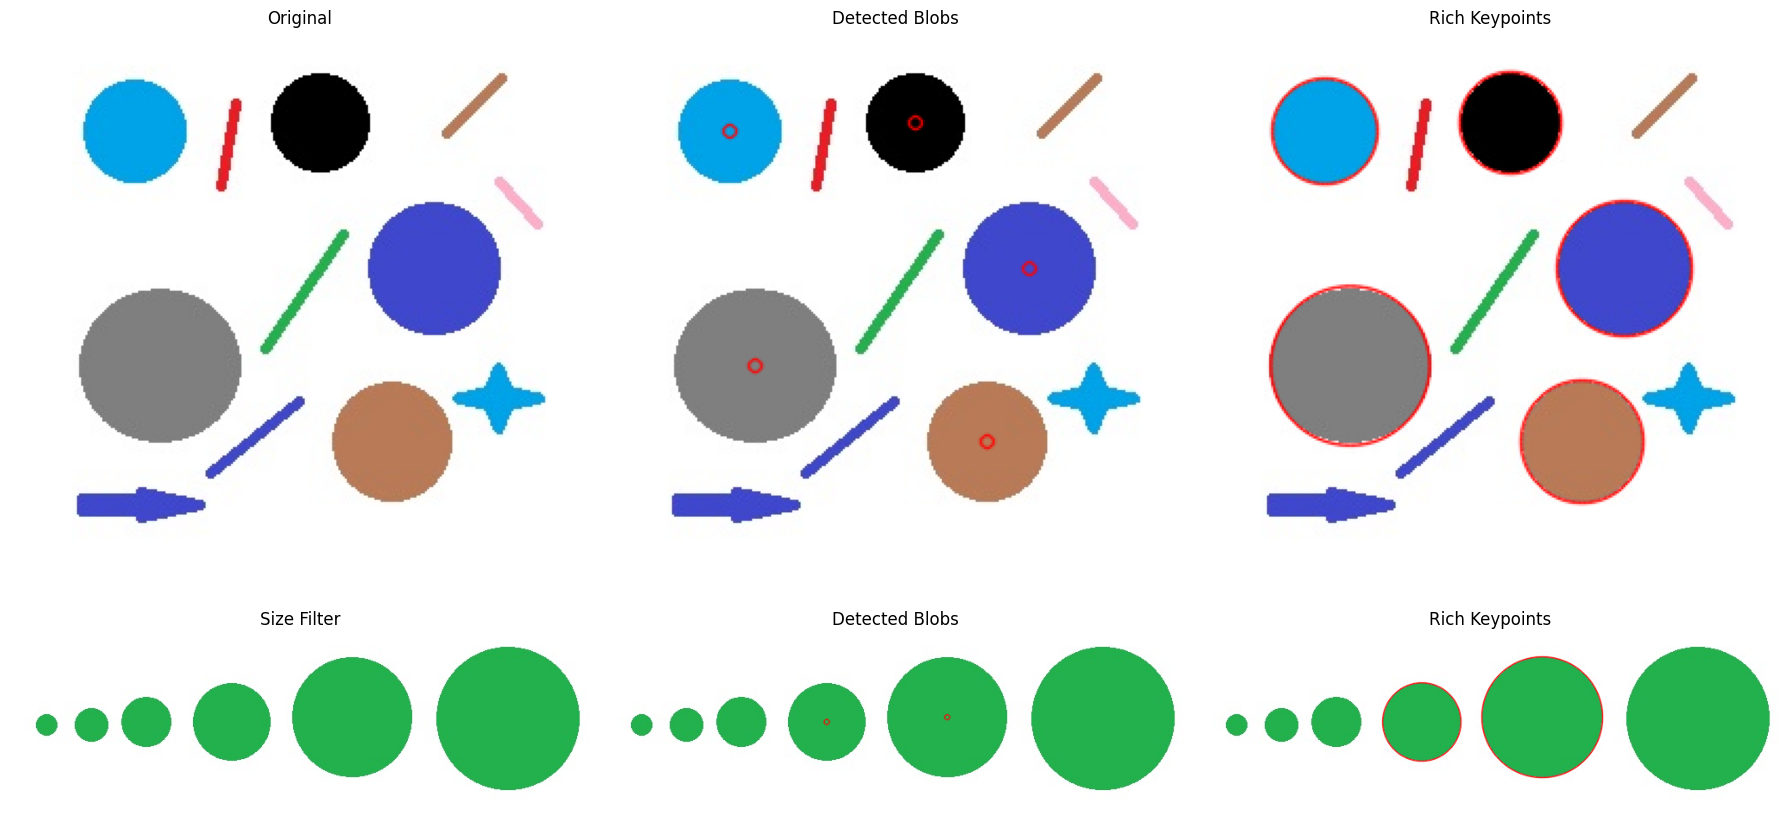

In [22]:
comparison_images = [
    default_image, default_result, default_rich_result,
    size_image, size_result, size_rich_result,
]

comparison_titles = [
    'Original', 'Detected Blobs', 'Rich Keypoints',
    'Size Filter', 'Detected Blobs', 'Rich Keypoints',
]

plt.figure(figsize=(18, 10))

for index, (image, title) in enumerate(zip(comparison_images, comparison_titles), start=1):
  plt.subplot(2, 3, index)
  plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
  plt.title(title)
  plt.axis('off')

plt.tight_layout()
plt.show()

In [24]:
output_images = {
    'Default': default_rich_result,
    'Size': size_rich_result,
    'Circularity': circularity_rich_result,
    'Convexity': convexity_rich_result,
    'Inertia': inertia_rich_result,
}

for filename, output_image in output_images.items():
  output_path = '/content/' + filename
  cv2.imwrite(f'{filename}.jpg', output_image)
  print(f'Saved {filename}.jpg')
  files.download(f'{filename}.jpg')
  print(f'Downloaded {filename}.jpg')

Saved Default.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded Default.jpg
Saved Size.jpg


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

Downloaded Convexity.jpg
Saved Inertia.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded Inertia.jpg
